# Differentiable Ship-D in JAX — paper reproduction & sensitivity analysis

This notebook exercises the **`shipd_jax`** package (a differentiable JAX port of the
Ship-D hull parameterization, validated to near machine precision against the original
implementation) on the analyses of *Bagazinski & Ahmed (2023), "Ship-D: Ship Hull
Dataset for Design Optimization Using Machine Learning"*, and on tooling built on top
of it:

1. **Solver validation — Figure 6**: Michell integral on the analytic Wigley hull.
2. **Figure 7 reproduction**: wave-drag coefficient of the DTMB 5415 reconstruction
   vs. towing-tank data.
3. **dCw/dFn** — the derivative of wave drag with respect to Froude number, via `jax.grad`.
4. **Design-space derivatives** — Jacobians of resistance and of all 49 feasibility
   constraints, and the **KKT matrix** of the drag-minimization problem at several
   Froude numbers.
5. The package **demo** (constraints, hydrostatics, drag and their gradients).
6. **3D hull surfaces** and waterline plan views.
7. The paper's **Chamfer similarity** metric (Eq. 1) comparing `shipd_jax` geometry
   with the original implementation, hull by hull.
8. **Traditional lines drawings and body plans** — profile/sheer plan, half-breadth
   plan, and body plan, built from the differentiable surface.
9. **Surface sensitivity to a design variable** — which parts of the hull move, and
   how much, when one design variable changes.
10. **Surface sensitivity to resistance and to constraints** — the steepest-ascent
    shape-deformation field for $R_w$, $C_w$, or any single feasibility constraint.

All plotting in this notebook goes through the reusable functions in
**`shipd_jax.viz`** (imported as `viz`) rather than one-off matplotlib code, so every
figure here can be reproduced or restyled with one function call elsewhere.

**Compilation reuse**: every expensive function is `jax.jit`-compiled **once** — with
the Froude number, speed, offsets, or tangent direction as *traced arguments* — and
then reused across drafts, speeds, design variables, and objectives. Sections 9 and
10 in particular share a **single** compiled surface-Jacobian-vector-product kernel
across every design variable and every objective they examine. Timings printed
throughout show first-call (compile) vs. steady-state cost.

In [1]:
import os, sys, time
import numpy as np
import jax
import jax.numpy as jnp
jax.config.update('jax_enable_x64', True)

import matplotlib.pyplot as plt

ROOT = os.path.abspath('..') if os.path.exists(os.path.join('..', 'Input_Vectors_SampleHulls.csv')) \
       else os.path.abspath('.')
sys.path.insert(0, ROOT)

from shipd_jax import (bits_from_vector, constraints,
                       build_volume_plan, build_cw_plan,
                       gen_pointcloud, volume_properties, gen_pc_for_cw,
                       mod_michell, calc_cf)
from shipd_jax import viz

G, RHO = 9.81, 1000.0
PARAM_LABELS = viz.PARAM_LABELS   # the 45 design-variable names, in vector order

VEC = np.loadtxt(os.path.join(ROOT, 'Input_Vectors_SampleHulls.csv'), delimiter=',')
HULL_NAMES = ['Container Ship', 'USS Zumwalt', 'Fast Ferry', 'Recreational Fishing Boat',
              'USS Freedom (LCS)', 'USS Nimitz', 'Sailing Yacht', 'Tug Boat',
              'USS Indianapolis', 'X-Bow', 'Wigley Hull', 'DTMB 5415']   # paper Table 1, A)-L)

x5415_np = VEC[11]                       # hull L) of the paper
x5415 = jnp.asarray(x5415_np)
LOA_5415 = float(x5415_np[0])

paper = np.load(os.path.join(ROOT, 'shipd_jax', 'paper_data', 'digitized_figs.npz'))

# ---- the single compiled Michell kernel used throughout this notebook ----
# Y:(301,51), U scalar, X:(301,), Z:(51,) -> compiled once, reused for the
# Wigley hull and for every draft/speed of the DTMB 5415.
michell_j = jax.jit(lambda Y, U, X, Z: mod_michell(Y, U, X, Z, RHO, 21))
print('setup complete')

setup complete


## 1. Solver validation — reproducing Figure 6 (Wigley hull)

Figure 6 of the paper verifies the numerical Michell integral (301 stations x 51
waterlines) against the analytic solution for the **Wigley hull**
$y = \tfrac{B}{2}\bigl(1-\xi^2\bigr)\bigl(1-(z/T)^2\bigr)$ with $B/L = 0.1$, $T/L = 0.0625$.

Matching the paper's y-axis fixes the normalization convention once and for all:
$$C_w = \frac{R_w}{\rho\,U^2\,L^2}$$
(no $\tfrac12$ — verified below to overlay the digitized paper curve).

Michell kernel: compile 0.5s; 107 speeds in 0.06s (0.5 ms/speed)


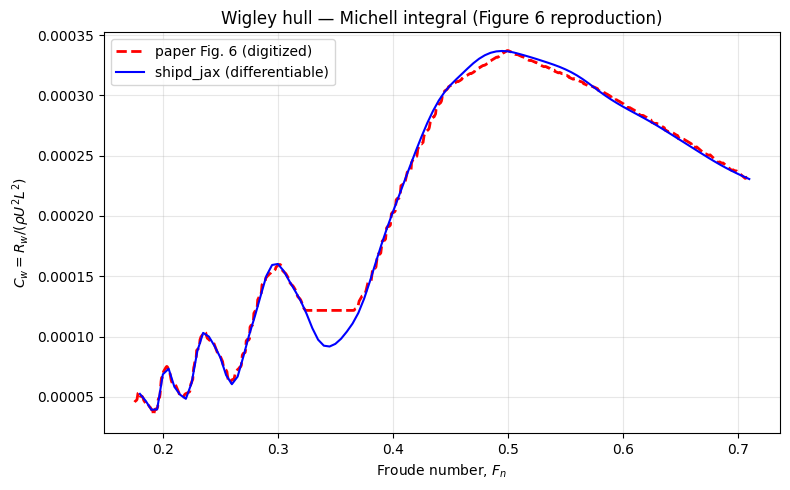

max |ours - paper curve| = 8.95e-06 (digitization-limited)


In [2]:
L_w, B_w, T_w = 10.0, 1.0, 0.625
Nx, Nz = 301, 51
Xw = np.linspace(0.0, L_w, Nx)
Zw = np.linspace(-T_w, 0.0, Nz)
Yw = np.maximum((B_w / 2) * (1 - (2 * Xw[:, None] / L_w - 1) ** 2)
                * (1 - (Zw[None, :] / T_w) ** 2), 0.0)

fns6 = np.arange(0.18, 0.711, 0.005)

t0 = time.time()
_ = float(michell_j(Yw, 0.3 * np.sqrt(G * L_w), Xw, Zw))
t_compile = time.time() - t0
t0 = time.time()
cw6 = np.array([float(michell_j(Yw, fn * np.sqrt(G * L_w), Xw, Zw))
                / (RHO * (fn * np.sqrt(G * L_w)) ** 2 * L_w ** 2) for fn in fns6])
t_curve = time.time() - t0
print(f'Michell kernel: compile {t_compile:.1f}s; {len(fns6)} speeds in {t_curve:.2f}s '
      f'({1e3*t_curve/len(fns6):.1f} ms/speed)')

pm = paper['fig6_michell']
fig, ax = plt.subplots(figsize=(8, 5))
viz.plot_michell_validation(fns6, cw6, cw_reference=(pm[:, 0], pm[:, 1]),
                            ref_label='paper Fig. 6 (digitized)',
                            title='Wigley hull — Michell integral (Figure 6 reproduction)', ax=ax)
plt.tight_layout(); plt.show()

interp_ours = np.interp(pm[:, 0], fns6, cw6)
print(f'max |ours - paper curve| = {np.max(np.abs(interp_ours - pm[:, 1])):.2e} '
      f'(digitization-limited)')

## 2. Figure 7 reproduction — DTMB 5415 wave drag vs. towing tank

Figure 7 compares the Michell $C_w$ of the parameterized **DTMB 5415** reconstruction
(hull *L* of Table 1 = row 11 of the sample vectors) against towing-tank total ($C_t$)
and residual ($C_r$) resistance coefficients.

The paper does not record the draft used. The real 5415 design draft is
$T \approx 6.15\,$m for a hull depth of $\approx 12.5\,$m at $L_{OA}=153.3$ m, i.e.
$T/D \approx 0.5{-}0.6$ of the reconstruction's depth parameter, so we plot the curve
at drafts $0.5\,D_d$, $0.6\,D_d$ and $0.67\,D_d$ (the paper's own digitized curve is shown
in grey). The Michell kernel compiled in Section 1 is **reused unchanged** — only the
offset grid per draft is rebuilt (a cheap forward evaluation).

3 drafts x 73 speeds in 7.0s (compiled kernel reused)


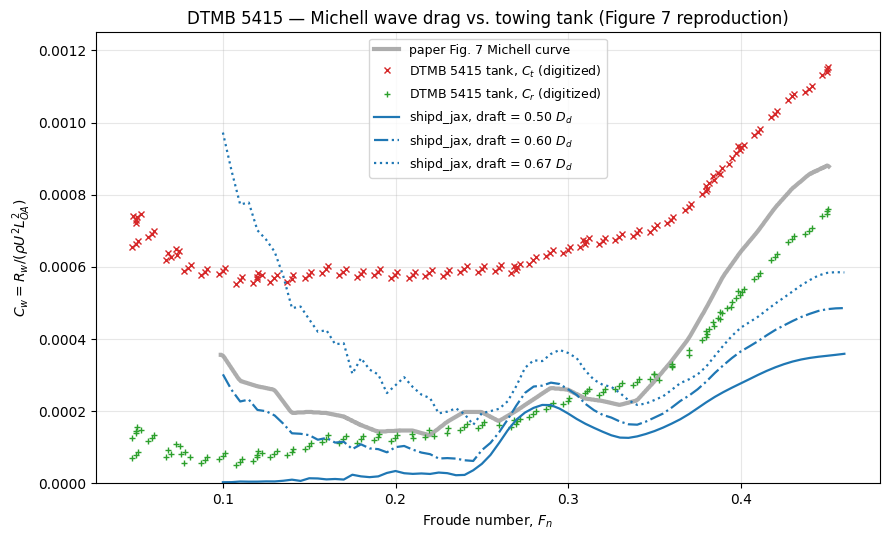

In the displacement range Fn 0.20-0.35 the curve at ~0.6 Dd tracks the tank Cr data
and the paper curve; the low-Fn oscillations and the steep tail are sensitive to the
exact draft and reconstruction vector, which Figure 7 does not record.


In [3]:
fns7 = np.arange(0.10, 0.461, 0.005)
curves = {}
grids = {}
t0 = time.time()
for tf in (0.50, 0.60, 0.67):
    plan = build_cw_plan(x5415_np, tf, num_wl=51, ppw=301)
    X, Z, Y, WL = gen_pc_for_cw(x5415, plan)
    WLc = float(WL)
    grids[tf] = (np.asarray(X), np.asarray(Z), np.asarray(Y), WLc)
    U = fns7 * np.sqrt(G * WLc)
    curves[tf] = np.array([float(michell_j(Y, u, X, Z)) for u in U]) / (RHO * U ** 2 * LOA_5415 ** 2)
print(f'3 drafts x {len(fns7)} speeds in {time.time()-t0:.1f}s (compiled kernel reused)')

ct, cr, pmich = paper['fig7_ct'], paper['fig7_cr'], paper['fig7_michell']
fig, ax = plt.subplots(figsize=(9, 5.5))
viz.plot_resistance_vs_froude(
    fns7,
    curves={f'shipd_jax, draft = {tf:.2f} $D_d$': curves[tf] for tf in curves},
    tank_points={'DTMB 5415 tank, $C_t$ (digitized)': (ct[:, 0], ct[:, 1]),
                'DTMB 5415 tank, $C_r$ (digitized)': (cr[:, 0], cr[:, 1])},
    reference_curve=(pmich[:, 0], pmich[:, 1]), reference_label='paper Fig. 7 Michell curve',
    ylabel='$C_w = R_w/(\\rho U^2 L_{OA}^2)$',
    title='DTMB 5415 — Michell wave drag vs. towing tank (Figure 7 reproduction)',
    ylim=(0, 0.00125), ax=ax)
plt.tight_layout(); plt.show()

print('In the displacement range Fn 0.20-0.35 the curve at ~0.6 Dd tracks the tank Cr data')
print('and the paper curve; the low-Fn oscillations and the steep tail are sensitive to the')
print('exact draft and reconstruction vector, which Figure 7 does not record.')

## 3. $dC_w/dF_n$ — differentiating the resistance curve

Because the whole pipeline is differentiable, the slope of the wave-drag curve is one
`jax.value_and_grad` away. At a fixed draft the offset grid does not depend on $F_n$
($F_n$ enters through $U$ and the normalization only), so this is the exact total
derivative. We `vmap` the value-and-gradient over a dense $F_n$ grid — a single
compilation evaluates both the curve and its derivative everywhere.

Zero crossings of $dC_w/dF_n$ are the **humps and hollows** of the wave-resistance
curve — the classic targets of hull-speed selection.

value+grad over 143 Froude numbers: compile 2.2s, reuse 0.057s


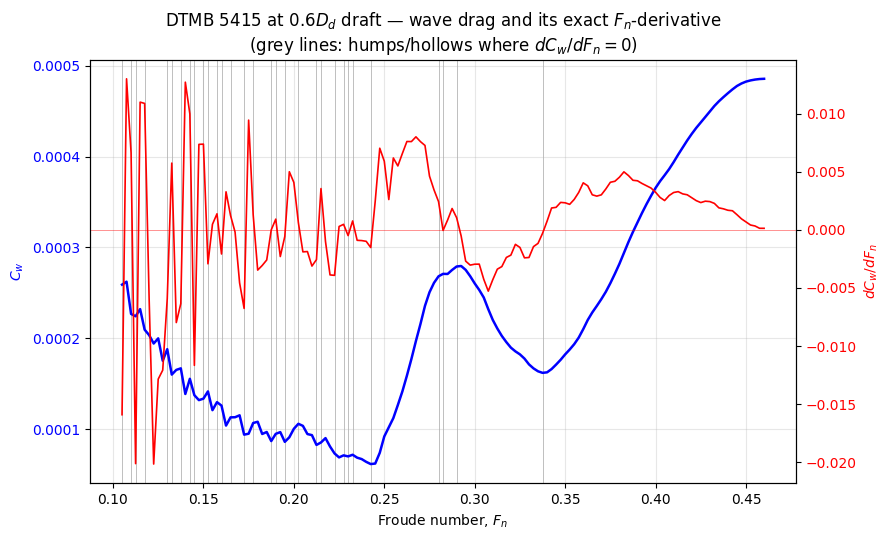

In [4]:
X6, Z6, Y6, WL6 = grids[0.60]
X6j, Z6j, Y6j = jnp.asarray(X6), jnp.asarray(Z6), jnp.asarray(Y6)

def cw_of_fn(fn):
    U = fn * jnp.sqrt(G * WL6)
    return mod_michell(Y6j, U, X6j, Z6j, RHO, 21) / (RHO * U ** 2 * LOA_5415 ** 2)

fns_dense = jnp.asarray(np.arange(0.105, 0.4601, 0.0025))
vg = jax.jit(jax.vmap(jax.value_and_grad(cw_of_fn)))
t0 = time.time(); cw_v, dcw = vg(fns_dense); cw_v.block_until_ready()
t_c = time.time() - t0
t0 = time.time(); cw_v, dcw = vg(fns_dense); cw_v.block_until_ready()
print(f'value+grad over {len(fns_dense)} Froude numbers: compile {t_c:.1f}s, reuse {time.time()-t0:.3f}s')

cw_v, dcw = np.asarray(cw_v), np.asarray(dcw)
fig, ax = plt.subplots(figsize=(9, 5.5))
viz.plot_dcw_dfn(fns_dense, cw_v, dcw, ax=ax,
                 title='DTMB 5415 at 0.6$D_d$ draft — wave drag and its exact $F_n$-derivative\n'
                      '(grey lines: humps/hollows where $dC_w/dF_n = 0$)')
plt.tight_layout(); plt.show()

## 4. Design-space derivatives and KKT matrices

Consider the drag-minimization problem over the 45 design variables $x$:

$$\min_x\; C_w(x; F_n) \quad \text{s.t.}\quad c(x) \le 0 \;\; (49 \text{ constraints})$$

Its KKT system at a point $(x, \lambda)$ is built from the objective gradient
$\nabla C_w$, the constraint Jacobian $J_c = \partial c/\partial x$, and the Lagrangian
Hessian. At the (feasible) sample hull no constraint is active, so $\lambda = 0$ and the
Hessian block is $H = \nabla^2 C_w$. We assemble

$$K(F_n) \;=\; \begin{bmatrix} \nabla^2 C_w(x;F_n) & J_A^{\top} \\ J_A & 0 \end{bmatrix}$$

with $J_A$ the rows of the *near-active* constraints (largest $c$ values), at several
Froude numbers of interest. All blocks are exact autodiff quantities:
$J_c$ by `jacfwd`, $H$ by forward-over-reverse (`jacfwd(grad(...))`), each compiled
**once** with $F_n$ as a traced argument and reused.

A reduced Michell grid (21x101) keeps XLA compile times reasonable; the derivative
structure is resolution-independent.

grad(Cw) compile 38s; all 4 Froude numbers reused in 0.02s


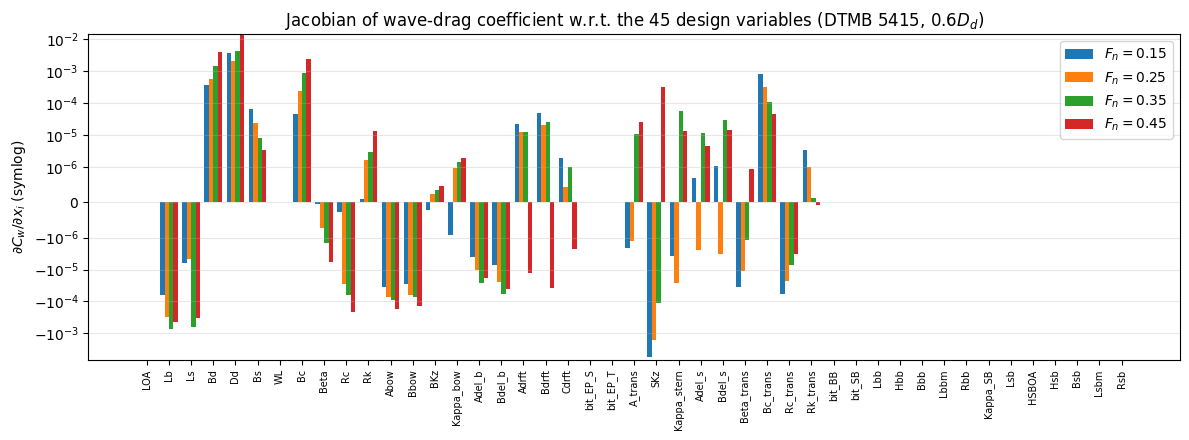

In [5]:
FNS_INT = [0.15, 0.25, 0.35, 0.45]
cwp_small = build_cw_plan(x5415_np, 0.60, num_wl=21, ppw=101)

def cw_x(xv, fn):
    X, Z, Y, WL = gen_pc_for_cw(xv, cwp_small)
    U = fn * jnp.sqrt(G * WL)
    return mod_michell(Y, U, X, Z, RHO, 21) / (RHO * U ** 2 * xv[0] ** 2)

grad_cw = jax.jit(jax.grad(cw_x, argnums=0))
t0 = time.time(); g0 = np.asarray(grad_cw(x5415, FNS_INT[0])); t_c = time.time() - t0
t0 = time.time(); grads = {fn: np.asarray(grad_cw(x5415, fn)) for fn in FNS_INT}
print(f'grad(Cw) compile {t_c:.0f}s; all {len(FNS_INT)} Froude numbers reused in {time.time()-t0:.2f}s')

fig, ax = plt.subplots(figsize=(12, 4.5))
viz.plot_param_gradient_bars({f'$F_n={fn}$': grads[fn] for fn in FNS_INT}, ax=ax,
                             ylabel='$\\partial C_w/\\partial x_i$ (symlog)',
                             title='Jacobian of wave-drag coefficient w.r.t. the 45 design variables (DTMB 5415, 0.6$D_d$)')
plt.tight_layout(); plt.show()

constraints: 0 violated of 49 (all <= 0 means feasible); Jacobian (49, 45)


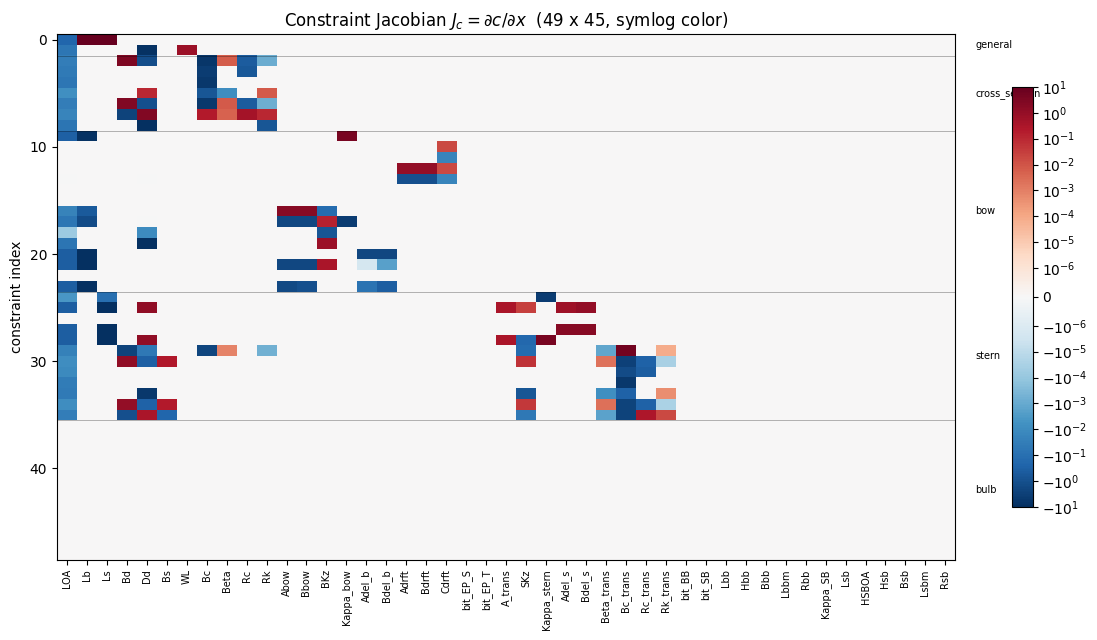

In [6]:
# ---- constraint values and Jacobian ----
bits11 = bits_from_vector(x5415_np)
c_val = np.asarray(constraints(x5415, bits11))
Jc = np.asarray(jax.jit(jax.jacfwd(lambda v: constraints(v, bits11)))(x5415))
print(f'constraints: {np.sum(c_val > 0)} violated of 49 (all <= 0 means feasible); '
      f'Jacobian {Jc.shape}')

fig, ax = plt.subplots(figsize=(12, 6.5))
viz.plot_constraint_jacobian(Jc, ax=ax,
                             title='Constraint Jacobian $J_c = \\partial c/\\partial x$  (49 x 45, symlog color)')
plt.tight_layout(); plt.show()

Hessian (45x45, forward-over-reverse) compile 251s; 4 Froude numbers reused in 0.12s
near-active constraints (index: value): {5: -0.074, 7: -0.1646, 11: -0.0873, 18: -0.0007, 24: -0.04, 30: -0.0881, 31: -0.117, 34: -0.0899}


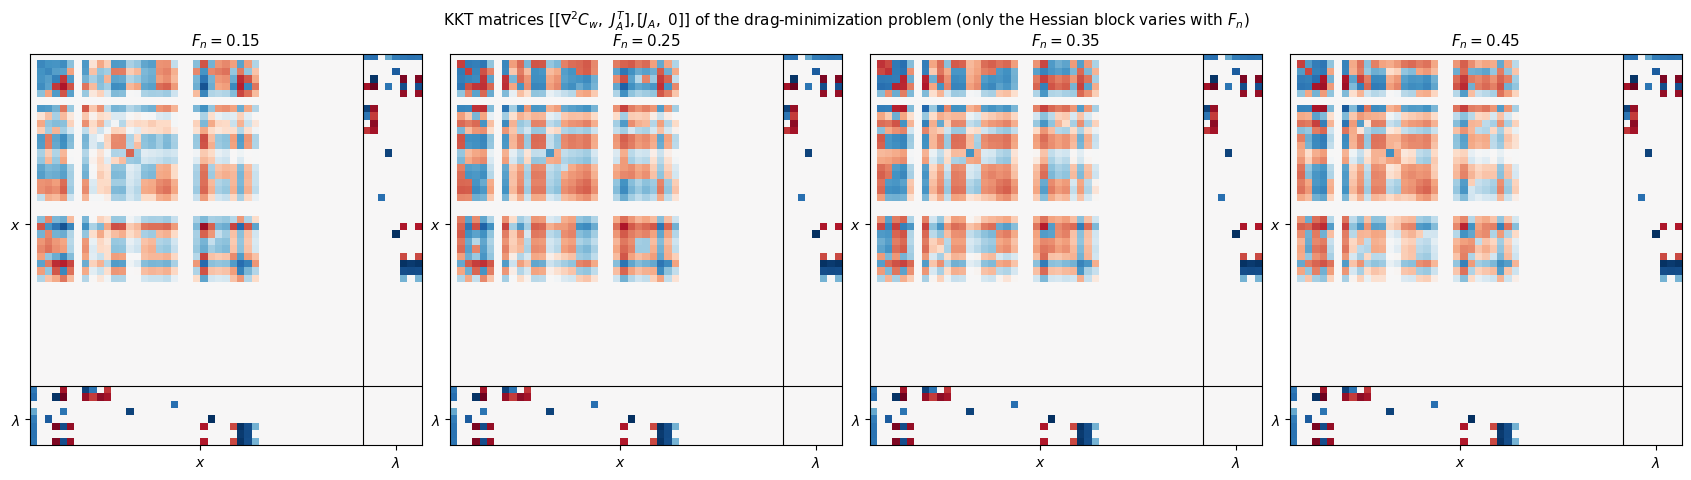

Fn=0.15: Hessian eigenvalue range [-1.033e-01, +3.235e-01] -> indefinite
Fn=0.25: Hessian eigenvalue range [-3.145e-02, +9.677e-02] -> indefinite
Fn=0.35: Hessian eigenvalue range [-6.426e-02, +6.470e-02] -> indefinite
Fn=0.45: Hessian eigenvalue range [-1.744e-01, +2.296e-01] -> indefinite


In [7]:
# ---- Lagrangian Hessian (= Hessian of Cw here) and KKT matrices ----
hess_cw = jax.jit(jax.jacfwd(jax.grad(cw_x, argnums=0), argnums=0))
t0 = time.time(); H0 = np.asarray(hess_cw(x5415, FNS_INT[0])); t_c = time.time() - t0
t0 = time.time(); hessians = {fn: np.asarray(hess_cw(x5415, fn)) for fn in FNS_INT}
print(f'Hessian (45x45, forward-over-reverse) compile {t_c:.0f}s; '
      f'{len(FNS_INT)} Froude numbers reused in {time.time()-t0:.2f}s')

# near-active set: the 8 constraints closest to their bounds
order = np.argsort(-c_val)
active = np.sort(order[:8])
JA = Jc[active]
print('near-active constraints (index: value):',
      {int(k): round(float(c_val[k]), 4) for k in active})

fig, axes = viz.plot_kkt_matrices({f'$F_n = {fn}$': hessians[fn] for fn in FNS_INT}, JA,
                                  suptitle='KKT matrices $[[\\nabla^2 C_w,\\ J_A^T],[J_A,\\ 0]]$ of the '
                                          'drag-minimization problem (only the Hessian block varies with $F_n$)')
plt.show()

for fn in FNS_INT:
    ev, kind = viz.hessian_definiteness(hessians[fn])
    print(f'Fn={fn}: Hessian eigenvalue range [{ev[0]:+.3e}, {ev[-1]:+.3e}] -> {kind}')

## 5. Package demo — hydrostatics, drag and their gradients

The condensed `shipd_jax.demo`: constraint feasibility, displaced volume and total-drag
gradients (which design variables matter), with compiled-call timings.

grad(volume) compile 62s
grad(total drag) compile 154s
grad(total drag) reuse at new Fn: 0.006s

DTMB 5415 reconstruction: displaced volume to deck = 5.675 m^3, total drag(Fn=0.30, T=0.6Dd) = 310.11 N


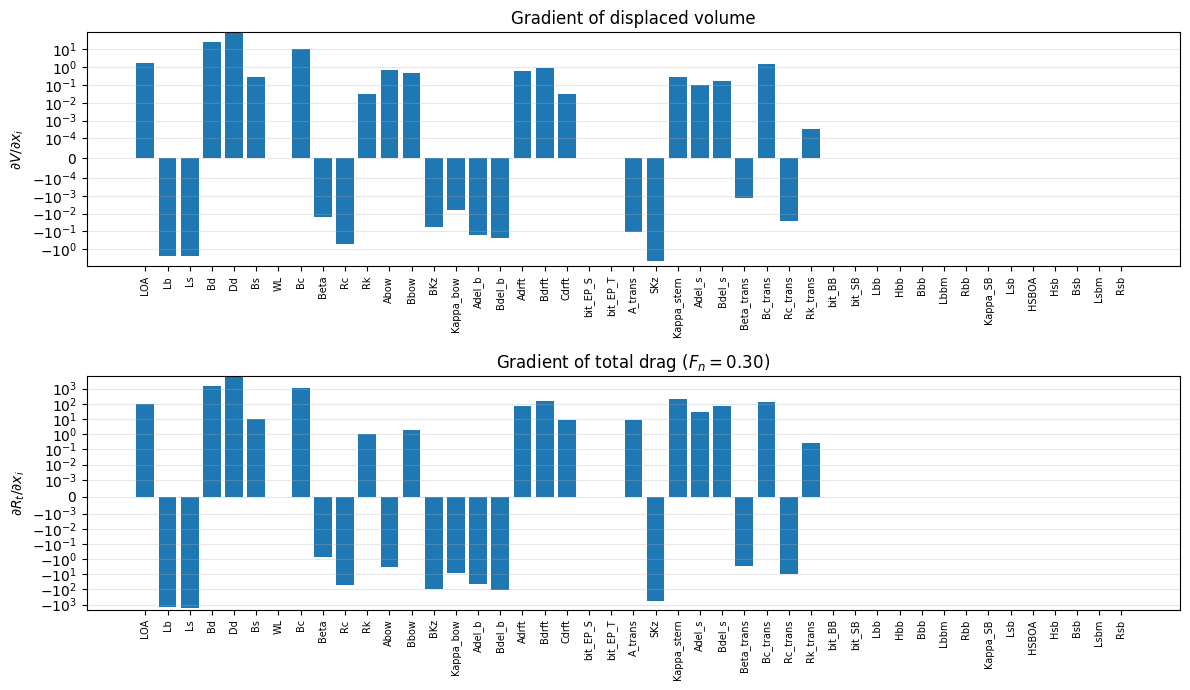

In [8]:
vol_plan_small = build_volume_plan(x5415_np, num_wl=21, ppw=101)

def vol_total(xv):
    return volume_properties(xv, vol_plan_small)['volumes'][-1]

def total_drag(xv, fn):
    X, Z, Y, WL = gen_pc_for_cw(xv, cwp_small)
    U = fn * jnp.sqrt(G * WL)
    Rw = mod_michell(Y, U, X, Z, RHO, 21)
    pr = volume_properties(xv, vol_plan_small)
    SA = jnp.interp(0.60 * pr['hull'].Dd, pr['Z'], pr['area_ws'])
    Rf = 0.5 * calc_cf(U, WL) * RHO * SA * U ** 2.0
    return Rw + Rf

grad_vol = jax.jit(jax.grad(vol_total))
grad_drag = jax.jit(jax.grad(total_drag, argnums=0))
drag_j = jax.jit(total_drag)

t0 = time.time(); gv = np.asarray(grad_vol(x5415)); print(f'grad(volume) compile {time.time()-t0:.0f}s')
t0 = time.time(); gd = np.asarray(grad_drag(x5415, 0.30)); print(f'grad(total drag) compile {time.time()-t0:.0f}s')
t0 = time.time(); _ = np.asarray(grad_drag(x5415, 0.35)); print(f'grad(total drag) reuse at new Fn: {time.time()-t0:.3f}s')

D0 = float(drag_j(x5415, 0.30))
V0 = float(vol_total(x5415))
print(f'\nDTMB 5415 reconstruction: displaced volume to deck = {V0:.3f} m^3, '
      f'total drag(Fn=0.30, T=0.6Dd) = {D0:.2f} N')

fig, axes = plt.subplots(2, 1, figsize=(12, 7))
viz.plot_param_gradient_bars(gv, ax=axes[0], ylabel='$\\partial V/\\partial x_i$',
                             title='Gradient of displaced volume', linthresh=1e-4)
viz.plot_param_gradient_bars(gd, ax=axes[1], ylabel='$\\partial R_t/\\partial x_i$',
                             title='Gradient of total drag ($F_n=0.30$)', linthresh=1e-3)
plt.tight_layout(); plt.show()

## 6. 3D hull surfaces and waterline plan view

The differentiable surface itself: the `(num_wl, ppw, 3)` point grid mirrored to both
sides, via `viz.plot_hull_3d`. This grid (`plan3d`/`pc5415` below) is reused again in
Sections 8-10 for the lines drawing and the shape-sensitivity fields, so it is built
once here at visualization resolution (higher than the gradient-computation plans
above, which stay small for fast compiles).

two hull grids built in 31.4s


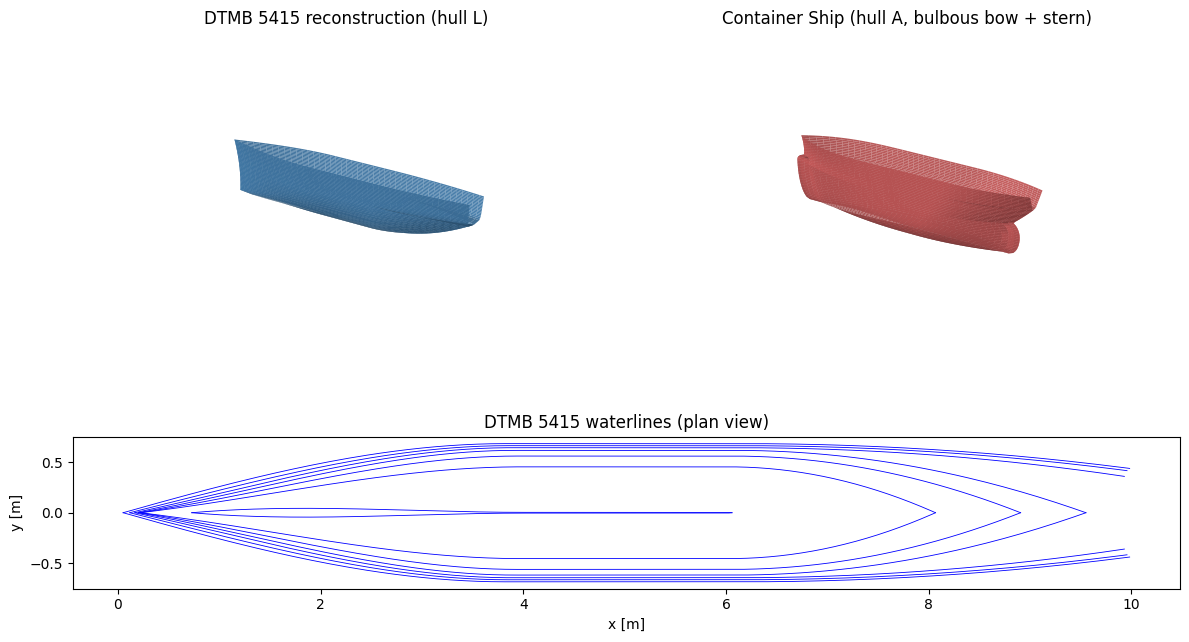

In [9]:
t0 = time.time()
plan3d = build_volume_plan(x5415_np, num_wl=41, ppw=220)
pc5415 = np.asarray(gen_pointcloud(x5415, plan3d))
plan_cont = build_volume_plan(VEC[0], num_wl=41, ppw=220)
pc_cont = np.asarray(gen_pointcloud(jnp.asarray(VEC[0]), plan_cont))
print(f'two hull grids built in {time.time()-t0:.1f}s')

fig = plt.figure(figsize=(12, 7))
ax1 = fig.add_subplot(221, projection='3d')
viz.plot_hull_3d(pc5415, ax=ax1, color='steelblue', title='DTMB 5415 reconstruction (hull L)')
ax2 = fig.add_subplot(222, projection='3d')
viz.plot_hull_3d(pc_cont, ax=ax2, color='indianred', title='Container Ship (hull A, bulbous bow + stern)')
ax3 = fig.add_subplot(212)
viz.plot_waterlines_plan(pc5415, ax=ax3, title='DTMB 5415 waterlines (plan view)')
plt.tight_layout(); plt.show()

## 7. Chamfer similarity — `shipd_jax` vs. the original implementation

The paper (Eq. 1) scores hull reconstructions with the *bidirectional mean of squared
Chamfer distances*; Table 1 reports its RMS as a percentage of $L_{OA}$ (target hull vs.
GA-fit parameterization, values 0.08%–0.56%). Here we apply the **same metric** to a
different question: how close is the `shipd_jax` surface to the *original
implementation's* surface for the identical design vector — i.e. geometric parity of the
differentiable rewrite, expressed in the paper's own currency.

hull                          RMS CD, jax vs original   paper Table 1 (recon vs target)
Container Ship                             7.16e-12 %                          0.343 %
USS Zumwalt                                7.70e-16 %                          0.252 %
Fast Ferry                                 1.21e-15 %                          0.277 %
Recreational Fishing Boat                  1.03e-14 %                          0.505 %
USS Freedom (LCS)                          2.74e-15 %                          0.402 %
USS Nimitz                                 4.62e-14 %                          0.342 %
Sailing Yacht                              3.33e-13 %                          0.397 %
Tug Boat                                   2.24e-11 %                          0.559 %
USS Indianapolis             (original implementation fails: LinAlgError)
X-Bow                                      1.88e-15 %                          0.390 %
Wigley Hull                                8.58e-16 %  

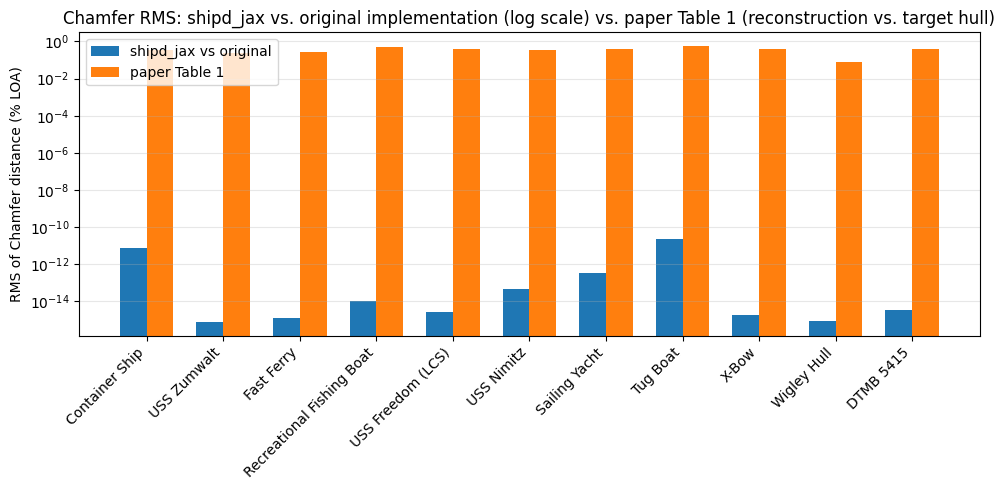

In [10]:
from scipy.spatial import cKDTree
import importlib.util, io
from contextlib import redirect_stdout
import matplotlib
spec = importlib.util.spec_from_file_location(
    'HP_ref', os.path.join(ROOT, 'spring_26_rewrite', 'HullParameterization.py'))
HP_ref = importlib.util.module_from_spec(spec); spec.loader.exec_module(HP_ref)

def chamfer_rms(A, B):
    dA = cKDTree(B).query(A)[0]
    dB = cKDTree(A).query(B)[0]
    cd = (np.sum(dA ** 2) + np.sum(dB ** 2)) / (len(A) + len(B))
    return np.sqrt(cd)

paper_table1 = [0.343, 0.252, 0.277, 0.505, 0.402, 0.342, 0.397, 0.559, 0.308,
                0.390, 0.0802, 0.401]   # RMS of CD as % LOA (paper Table 1)

names_ok, rms_ok, paper_ok, skipped = [], [], [], []
print(f'{"hull":28s} {"RMS CD, jax vs original":>24s}   {"paper Table 1 (recon vs target)":>30s}')
for i, name in enumerate(HULL_NAMES):
    v = VEC[i]
    try:
        ref = HP_ref.Hull_Parameterization(np.array(v))
        with redirect_stdout(io.StringIO()):
            ref.Calc_VolumeProperties(NUM_WL=51, PointsPerWL=300)
        pc_ref = np.asarray(ref.PCMeasurement).reshape(-1, 3)
    except Exception as e:
        skipped.append(name)
        print(f'{name:28s} {"(original implementation fails: " + type(e).__name__ + ")":>24s}')
        continue
    plan = build_volume_plan(v, num_wl=51, ppw=300)
    pc_jax = np.asarray(gen_pointcloud(jnp.asarray(v), plan)).reshape(-1, 3)
    rms = chamfer_rms(pc_jax, pc_ref) / v[0] * 100
    names_ok.append(name); rms_ok.append(rms); paper_ok.append(paper_table1[i])
    print(f'{name:28s} {rms:>22.2e} %   {paper_table1[i]:>28.3f} %')

print('\nThe rewrite is 10+ orders of magnitude closer to the original implementation than')
print('the parameterization itself is to the target hulls it was fit to.')

fig, ax = plt.subplots(figsize=(10, 5))
viz.plot_chamfer_comparison(names_ok, rms_ok, reference_pct=paper_ok, ax=ax,
                            title='Chamfer RMS: shipd_jax vs. original implementation (log scale) '
                                 'vs. paper Table 1 (reconstruction vs. target hull)')
plt.tight_layout(); plt.show()

## 8. Traditional lines drawing and body plan

Naval-architecture "lines drawings" present a hull through three orthogonal views:

* the **profile / sheer plan** — the keel-stem-sternpost-deck outline, plus *buttock
  lines* (constant lateral-offset longitudinal slices),
* the **half-breadth plan** — *waterlines* (constant-height slices), mirrored
  port/starboard,
* the **body plan** — *stations* (constant-x cross-sections), conventionally with
  forward stations drawn on the right of the centerline and aft stations on the left.

`viz.plot_lines_drawing` builds all three from a single `gen_pointcloud` grid — no new
differentiable geometry is needed, since every waterline row is already x-monotonic
bow-to-stern by construction, which is what makes station/buttock extraction by simple
interpolation well posed. `viz.plot_body_plan` is also usable standalone (shown below on
the bulbous-bow/stern Container Ship, reusing `pc_cont` from Section 6).

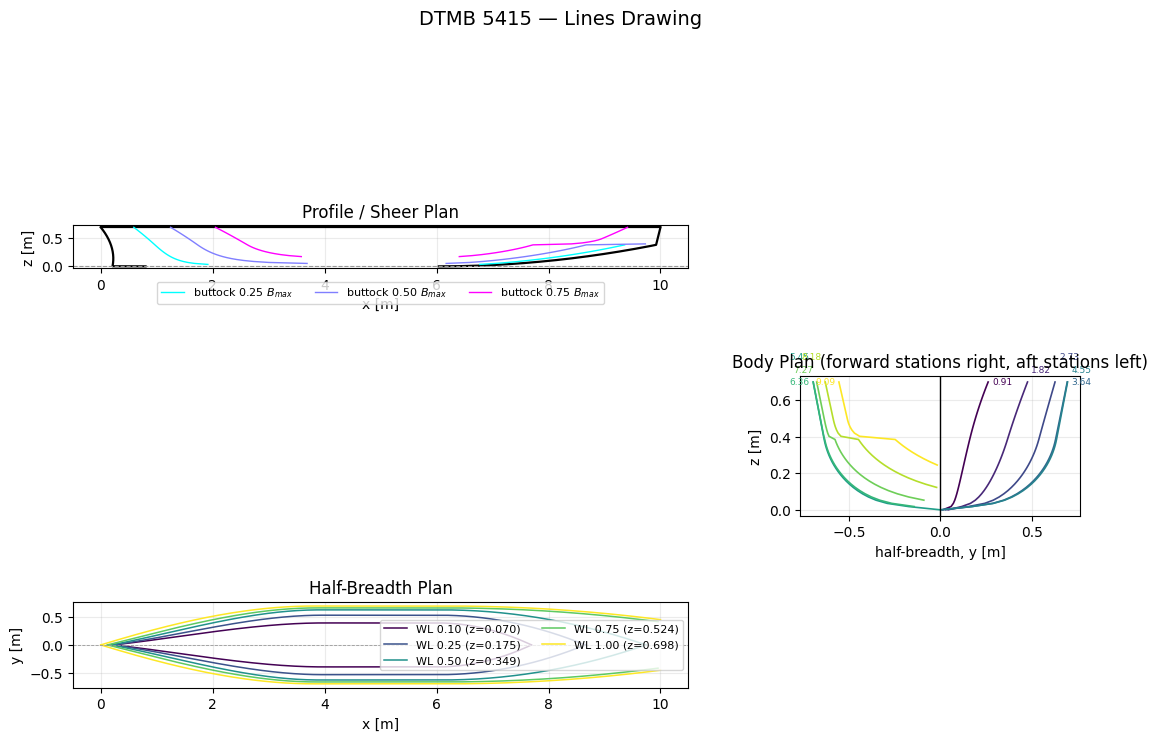

In [11]:
fig, axes = viz.plot_lines_drawing(x5415_np, plan3d, pc=pc5415, n_stations=10,
                                   title='DTMB 5415 — Lines Drawing')
plt.show()

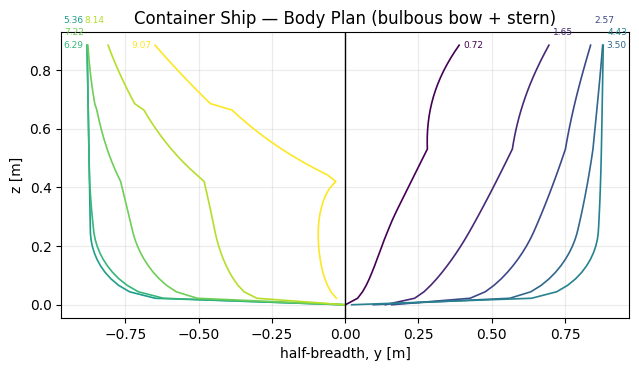

In [12]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
viz.plot_body_plan(VEC[0], plan_cont, pc=pc_cont, n_stations=10, ax=ax,
                   title='Container Ship — Body Plan (bulbous bow + stern)')
plt.tight_layout(); plt.show()

## 9. Surface sensitivity to a design variable

`viz.plot_param_sensitivity_3d` colors the hull surface by
$\lVert\partial p/\partial x_i\rVert$ for a chosen design variable $x_i$ — anything
*except* the four discrete "bit" switches (`bit_EP_S`, `bit_EP_T`, `bit_BB`, `bit_SB`),
which have no derivative and make the function raise `ValueError` (demonstrated below).

Calling that convenience function once per variable would retrace `gen_pointcloud`
every time, so instead we **jit the surface-JVP kernel a single time** — closing over
the same `plan3d` built in Section 6 — and reuse the compiled executable for every
tangent direction below, including the resistance/constraint directions of Section 10.

5 parameter sensitivities (1 compile + 4 reused calls) in 55.2s
Bbb sensitivity max = 0  (DTMB 5415 has bit_BB=0, so Bbb is dead -- confirms the zero)


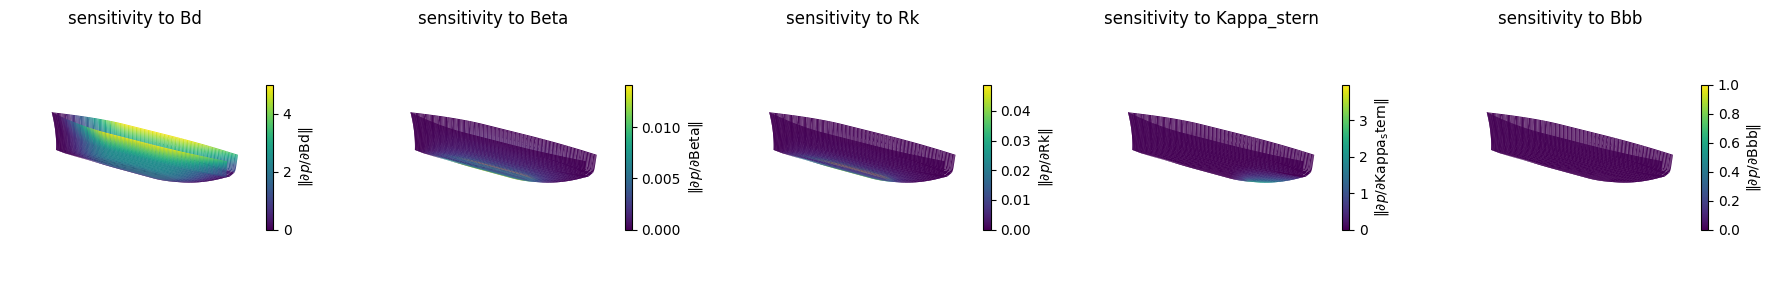


plot_param_sensitivity_3d correctly refuses a discrete bit parameter:
  parameter 'bit_BB' (index 31) is a discrete structural switch (0/1), not a continuous design variable, so it has no meaningful surface derivative. Choose a different parameter, or compare two plans bu...


In [13]:
surface_jvp = jax.jit(lambda xv, tangent:
                     jax.jvp(lambda v: gen_pointcloud(v, plan3d), (xv,), (tangent,))[1])

def param_field(name):
    idx = PARAM_LABELS.index(name)
    tangent = jnp.zeros(45).at[idx].set(1.0)
    dpc = np.asarray(surface_jvp(x5415, tangent))
    return np.linalg.norm(dpc, axis=-1)

# Bd, Beta, Rk, Kappa_stern are all "live" on the DTMB 5415; Bbb (bulbous-bow beam) is
# included deliberately as a control -- the 5415 reconstruction has bit_BB=0, so the
# surface never reads Bbb and its sensitivity field should come out exactly zero.
params_to_show = ['Bd', 'Beta', 'Rk', 'Kappa_stern', 'Bbb']

t0 = time.time()
fields = {name: param_field(name) for name in params_to_show}
print(f'{len(params_to_show)} parameter sensitivities (1 compile + {len(params_to_show)-1} reused '
      f'calls) in {time.time()-t0:.1f}s')
print(f"Bbb sensitivity max = {fields['Bbb'].max():.3g}  "
      f"(DTMB 5415 has bit_BB=0, so Bbb is dead -- confirms the zero)")

fig = plt.figure(figsize=(3.6 * len(params_to_show), 3.2))
for i, name in enumerate(params_to_show):
    ax = fig.add_subplot(1, len(params_to_show), i + 1, projection='3d')
    viz.plot_hull_surface_scalar(pc5415, fields[name], ax=ax, title=f'sensitivity to {name}',
                                 colorbar_label=f'$\\Vert\\partial p/\\partial \\mathrm{{{name}}}\\Vert$')
plt.tight_layout(); plt.show()

try:
    viz.plot_param_sensitivity_3d(x5415_np, plan3d, 'bit_BB')
except ValueError as e:
    print('\nplot_param_sensitivity_3d correctly refuses a discrete bit parameter:')
    print(' ', str(e)[:200] + '...')

## 10. Surface sensitivity to resistance and to constraints

`viz.make_resistance_objective` and `viz.make_constraint_objective` build scalar
`objective(x)` closures for $R_w$, $C_w$, or a single feasibility constraint.
`viz.surface_sensitivity_to_objective` computes `grad(objective)(x)`, normalizes it, and
pushes it through the surface-JVP kernel — the steepest-ascent shape-deformation field
for that objective: where the hull surface would move, and by how much, under a
gradient step that most increases $R_w$, $C_w$, or a constraint value.

Below we reuse the **same `surface_jvp` kernel compiled in Section 9** for the JVP half
of the computation (only `grad(objective)` pays its own, separate, one-time compile
per objective — each objective is a different computational graph). $R_w$ and $C_w$
are evaluated at $F_n=0.30$ on the reduced Michell plan (`cwp_small`) from Section 4;
the two constraints are the most- and least-slack of the near-active set (`active`)
identified there.

4 objective sensitivities in 25.5s (surface-JVP kernel reused throughout; each grad(objective) pays its own compile)


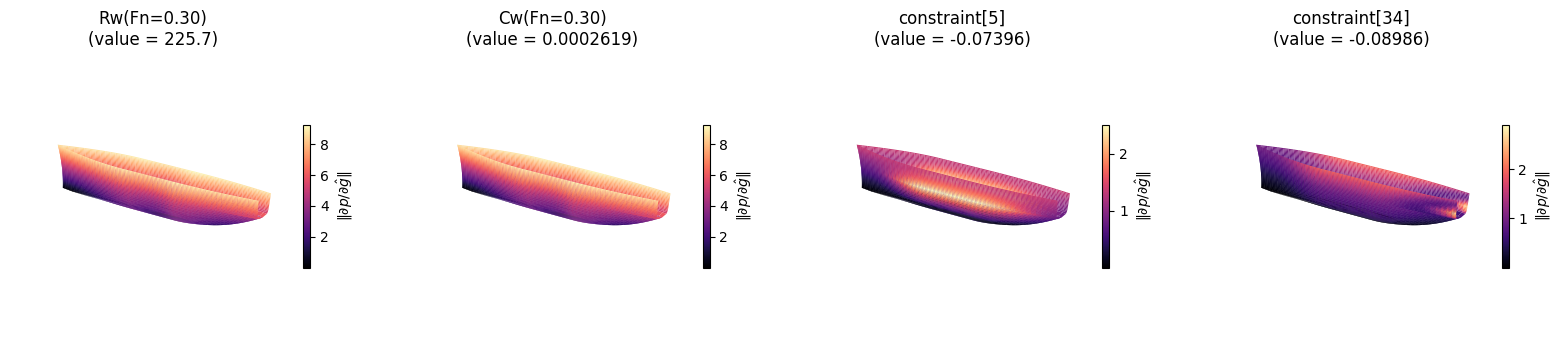

In [14]:
obj_rw = viz.make_resistance_objective(cwp_small, 0.30, mode='Rw')
obj_cw = viz.make_resistance_objective(cwp_small, 0.30, mode='Cw')
k1, k2 = int(active[0]), int(active[-1])
obj_c1 = viz.make_constraint_objective(bits11, k1)
obj_c2 = viz.make_constraint_objective(bits11, k2)

objectives = [('Rw(Fn=0.30)', obj_rw), ('Cw(Fn=0.30)', obj_cw),
              (f'constraint[{k1}]', obj_c1), (f'constraint[{k2}]', obj_c2)]

t0 = time.time()
results = {}
for name, obj in objectives:
    value, grad = jax.value_and_grad(obj)(x5415)
    gnorm = jnp.linalg.norm(grad)
    direction = grad / jnp.where(gnorm > 0, gnorm, 1.0)
    dpc = np.asarray(surface_jvp(x5415, direction))     # <-- same compiled kernel as Section 9
    results[name] = (np.linalg.norm(dpc, axis=-1), float(value))
print(f'{len(objectives)} objective sensitivities in {time.time()-t0:.1f}s '
      f'(surface-JVP kernel reused throughout; each grad(objective) pays its own compile)')

fig = plt.figure(figsize=(4.0 * len(objectives), 3.4))
for i, (name, (field, value)) in enumerate(results.items()):
    ax = fig.add_subplot(1, len(objectives), i + 1, projection='3d')
    viz.plot_hull_surface_scalar(pc5415, field, ax=ax, cmap='magma',
                                 title=f'{name}\n(value = {value:.4g})',
                                 colorbar_label=r'$\Vert\partial p/\partial \hat g\Vert$')
plt.tight_layout(); plt.show()

## Summary

* **Figure 6** (Wigley) reproduces the paper's Michell validation essentially exactly,
  pinning the coefficient convention $C_w = R_w/(\rho U^2 L^2)$.
* **Figure 7** (DTMB 5415): with the released reconstruction vector, the curve at the
  design-draft estimate ($\approx 0.6\,D_d$) tracks the tank $C_r$ data and the paper's
  curve through the displacement range; low-$F_n$ oscillations and the tail depend on
  the (unrecorded) draft/vector the authors used.
* $dC_w/dF_n$, $\partial C_w/\partial x$, $\partial c/\partial x$, and
  $\nabla^2 C_w$ (hence full **KKT matrices**) all come from exact autodiff, each
  compiled once and reused across Froude numbers.
* The `shipd_jax` surface matches the original implementation to a Chamfer RMS around
  $10^{-13}\% \cdot L_{OA}$ — geometric parity by the paper's own metric — while being
  fully differentiable end to end.
* Every plot above is a call into **`shipd_jax.viz`**, a reusable visualization module
  covering resistance curves, gradient/Jacobian/KKT diagnostics, 3D hull rendering,
  **traditional lines drawings and body plans**, and **surface-sensitivity fields for
  any design variable, for resistance ($R_w$/$C_w$), or for any constraint** — the last
  two built on a single compiled surface-JVP kernel reused across every direction
  examined.